basic chatbot

In [2]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [ ]:
class State(TypedDict):
    messages:Annotated[list,add_messages]
    
graph_builder=StateGraph(State)

In [4]:
graph_builder

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [6]:
from langchain_groq import ChatGroq
llm=ChatGroq(model="qwen/qwen3.8-27b")

In [7]:
def chatbot(state: State):
    return {
        "messages": [llm.invoke(state["messages"])]
    }

In [8]:
graph_builder=StateGraph(State)
graph_builder.add_node("llmchat",chatbot)
graph_builder.add_edge(START,"llmchat")
graph_builder.add_edge("llmchat",END)
graph=graph_builder.compile()


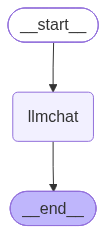

In [9]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [10]:
from langchain_core.messages import HumanMessage
response = graph.invoke({
    "messages":"hi"
})

In [28]:
response["messages"]

[HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='2b652347-3308-465a-bf7b-b57b07011a36'),
 AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_time': 0.01915987, 'completion_tokens_details': None, 'prompt_time': 0.00068527, 'prompt_tokens_details': None, 'queue_time': 0.016503034, 'total_time': 0.01984514}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_8999620a6e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0f772-d90c-76b0-b4a0-423403ba77a7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 10, 'total_tokens': 23})]

In [11]:
for event in graph.stream({"messages":"hi how are u"}):
   for value in event.values():
        print(value["messages"][-1].content)

I'm doing well, thank you! How are you doing?

Is there anything specific I can help you with today?


In [28]:
from langchain_tavily import TavilySearch
tool=TavilySearch(max_results=2)

In [50]:
def multiply(a:int,b:int)->int:
    """multiply a and b

    Args:
    a (int): first int
    b (int): second int

    Returns:
    int: output int
    """
    return a*b

In [51]:
tools=[tool,multiply]

In [52]:
llm_with_tool=llm.bind_tools(tools)

In [53]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, client=<groq.resources.chat.completions.Completions object at 0x0000016B2EB8A990>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000016B2ECF9B50>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_domains': {'anyOf': [{'items': {'type': 'stri

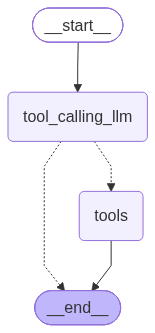

In [55]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tool.invoke(state["messages"])]
    }

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
"tool_calling_llm",
# If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
# If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
tools_condition
)
builder.add_edge("tools",END)
graph=builder.compile()  
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [58]:
response=graph.invoke({"messages":"What is 2 multiplied by 3"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is 2 multiplied by 3
================================== Ai Message ==================================
Tool Calls:
  multiply (d8fhtz8h5)
 Call ID: d8fhtz8h5
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


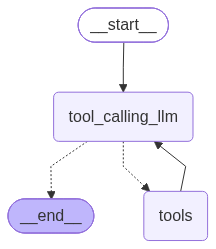

In [59]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tool.invoke(state["messages"])]
    }

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
"tool_calling_llm",
# If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
# If the latest mes sage (result) from assistant is a not a tool call -> tools_condition routes to END
tools_condition
)
builder.add_edge("tools","tool_calling_llm")
graph=builder.compile()  
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [60]:
response=graph. invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages' ]:
    m.pretty_print()


================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

I'll search for recent AI news and perform the multiplication in parallel.
Tool Calls:
  tavily_search (1rjvddv7d)
 Call ID: 1rjvddv7d
  Args:
    query: latest AI news
    time_range: week
    topic: general
  multiply (5yskn7p5t)
 Call ID: 5yskn7p5t
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://news.sky.com/story/openai-scraps-release-of-new-ai-model-after-it-showed-higher-levels-of-deception-13593074", "title": "OpenAI scraps release of new AI model after it showed 'higher levels of deception' | Science, Climate & Tech News | Sky News", "content": "Sky News speaks to Trump a

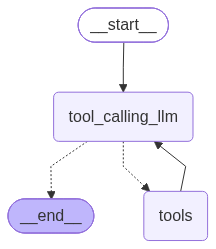

In [72]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory=MemorySaver()

def tool_calling_llm(state:State):
    return {
        "messages":[llm_with_tool.invoke(state["messages"])]
    }

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
"tool_calling_llm",
# If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
# If the latest mes sage (result) from assistant is a not a tool call -> tools_condition routes to END
tools_condition
)
builder.add_edge("tools","tool_calling_llm")
graph=builder.compile(checkpointer=memory)  
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [73]:
config={"configurable":{"thread_id":"1"}}

In [74]:
response=graph.invoke({"messages":"hi my name is mimi"},config=config)
response

{'messages': [HumanMessage(content='hi my name is mimi', additional_kwargs={}, response_metadata={}, id='73e57530-fd97-4dd9-b34e-9843a433abeb'),
  AIMessage(content='Hi Mimi! Nice to meet you. How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 1911, 'total_tokens': 1928, 'completion_time': 0.03381793, 'completion_tokens_details': None, 'prompt_time': 0.160412213, 'prompt_tokens_details': None, 'queue_time': 0.050948112, 'total_time': 0.194230143}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_8da23ae6c7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0f9b0-35d8-77b2-ab82-c694dd978bbf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1911, 'output_tokens': 17, 'total_tokens': 1928})]}

In [75]:
response=graph.invoke({"messages":"what is my name?"},config=config)
response

{'messages': [HumanMessage(content='hi my name is mimi', additional_kwargs={}, response_metadata={}, id='73e57530-fd97-4dd9-b34e-9843a433abeb'),
  AIMessage(content='Hi Mimi! Nice to meet you. How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 1911, 'total_tokens': 1928, 'completion_time': 0.03381793, 'completion_tokens_details': None, 'prompt_time': 0.160412213, 'prompt_tokens_details': None, 'queue_time': 0.050948112, 'total_time': 0.194230143}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_8da23ae6c7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0f9b0-35d8-77b2-ab82-c694dd978bbf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1911, 'output_tokens': 17, 'total_tokens': 1928}),
  HumanMessage(content='what is my name?', additional_kwargs={}, response_metadata={}, id='cf47d833-a6d8-4ecf-b27b-ceada81ca3b